## Preprocessing code

In [1]:
# python -m src.helpers.dataset_manager "dataset/train_images/train" "dataset/train_masks/train" --patch_size 512
# python -m src.helpers.dataset_manager "dataset/val_images/val" "dataset/val_masks/val" --type "val" --patch_size 512

## Imports & Setup

**Environment Configuration**

Sets up the TensorFlow/Keras environment for deep learning model training with the following key configurations:

**GPU Memory Management:**
- Detects available GPUs using `tf.config.list_physical_devices('GPU')`
- Enables dynamic memory growth to prevent TensorFlow from allocating all GPU memory upfront

**Dataset Configuration:**
- `patch_size = 512`: Defines the size of image patches (512×512 pixels)
- `patch_dir_train` and `patch_dir_val`: Point to the preprocessed patch dataset directory
- Assumes dataset preparation (cropping, padding, patching, directory structure) is already complete

**Project Structure:**
- Dynamically locates the project root by navigating two levels up from the current directory
- Adds project root to `sys.path` to enable imports from the `src` module
- Imports custom metrics and loss functions: `f1`, `iou`, and `dice_bce_loss` from `src.inference.custom_functions`

**Key Libraries:**
- TensorFlow/Keras for model training
- NumPy for numerical operations
- Matplotlib for visualization
- scikit-learn for train/test splitting

In [ ]:
import os
import sys
import numpy as np
from pathlib import Path

import tensorflow as tf 
from keras.models import load_model
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split

2025-12-15 11:04:24.871874: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

In [4]:
# REQUIREMENT: Do not add code from Tasks 2 or 4
# REQUIREMENT: All dataset prep (crop/pad/patch/directory structure) must be finalize before attempting this task.
patch_size = 512

base = os.path.abspath(os.getcwd())
patch_dir_train = os.path.join(base, f"dataset_patches_{patch_size}px")
patch_dir_val = os.path.join(base, f"dataset_patches_{patch_size}px")

In [ ]:
# starting point = current working directory
cwd = Path().resolve()

# go two levels up (adjust as needed)
project_root = cwd.parents[1]

sys.path.insert(0, str(project_root))
from src.inference.custom_functions import f1, iou, dice_bce_loss

## Dataset Preparation & Data Generators

**Train/Validation Split Strategy**

Creates an 80/20 train-validation split from the original training dataset rather than using the designated validation set:

- **Rationale:** The original training dataset is very large, making a 20% split (3,420 patches) far more representative than the designated validation set (only 17 images/612 patches)
- **Split sizes:** 
  - Training: 80% (~13,680  patches)
  - Validation: 20% (~3,420  patches)
  - vs. designated validation: only 17 images total

**File Discovery & Split Creation:**

1. Recursively walks through `train_images` directory to find all `.png` files
2. Uses `train_test_split()` with `random_state=42` for reproducibility (80% train, 20% validation)
3. Creates temporary directory structure with required subdirectories for Keras `flow_from_directory()`:
   - `temp_train_images/data/` and `temp_train_masks/data/`
   - `temp_val_images/data/` and `temp_val_masks/data/`
4. Copies split files to their respective temporary directories using `shutil.copy()`

**Data Augmentation & Generators**

**Training Generators:**
- **Image augmentation:** Rescaling (1/255) + horizontal flipping for data diversity
- **Mask augmentation:** Horizontal flipping only (matches image transformations)
- Batch size: 64
- Shuffle enabled with `seed=42` for synchronized image-mask pairing
- RGB images, grayscale masks

**Validation Generators:**
- **Image augmentation:** Rescaling only (no flipping for consistent evaluation)
- **Mask augmentation:** None
- Batch size: 16
- Shuffle enabled with `seed=42`

**Custom Generator Functions:**
- `train_generator()` and `val_generator()` zip image and mask generators together
- Yield synchronized (image, mask) pairs for model training
- Infinite loops ensure continuous data flow during training epochs

In [ ]:
# Get all image files from train directory
train_images_dir = f'{patch_dir_train}/train_images'
train_masks_dir = f'{patch_dir_train}/train_masks'

# Assuming images are in subdirectories by class or just in one directory
# Get all image filenames
image_files = []
for root, dirs, files in os.walk(train_images_dir):
    for file in files:
        if file.endswith('.png'):
            rel_path = os.path.relpath(os.path.join(root, file), train_images_dir)
            image_files.append(rel_path)

# Split into train (80%) and validation (20%)
train_files, val_files = train_test_split(image_files, test_size=0.2, random_state=42)

# Create temporary directories for the split
import shutil
temp_train_img = f'{patch_dir_train}/temp_train_images'
temp_train_mask = f'{patch_dir_train}/temp_train_masks'
temp_val_img = f'{patch_dir_train}/temp_val_images'
temp_val_mask = f'{patch_dir_train}/temp_val_masks'

# Create directories
for d in [temp_train_img, temp_train_mask, temp_val_img, temp_val_mask]:
    os.makedirs(d, exist_ok=True)
    os.makedirs(os.path.join(d, 'data'), exist_ok=True)  # Subdirectory needed for flow_from_directory

# Copy files to temporary directories
for file in train_files:
    src_img = os.path.join(train_images_dir, file)
    src_mask = os.path.join(train_masks_dir, file)
    dst_img = os.path.join(temp_train_img, 'data', os.path.basename(file))
    dst_mask = os.path.join(temp_train_mask, 'data', os.path.basename(file))
    shutil.copy(src_img, dst_img)
    shutil.copy(src_mask, dst_mask)

for file in val_files:
    src_img = os.path.join(train_images_dir, file)
    src_mask = os.path.join(train_masks_dir, file)
    dst_img = os.path.join(temp_val_img, 'data', os.path.basename(file))
    dst_mask = os.path.join(temp_val_mask, 'data', os.path.basename(file))
    shutil.copy(src_img, dst_img)
    shutil.copy(src_mask, dst_mask)

# Setup generators for training (80% of original train data)
train_image_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True)
train_image_generator = train_image_datagen.flow_from_directory(
    temp_train_img,
    target_size=(patch_size, patch_size),
    batch_size=64,
    class_mode=None,
    color_mode='rgb',
    shuffle=True,
    seed=42)

train_mask_datagen = ImageDataGenerator(
    horizontal_flip=True)
train_mask_generator = train_mask_datagen.flow_from_directory(
    temp_train_mask,
    target_size=(patch_size, patch_size),
    batch_size=64,
    class_mode=None,
    color_mode='grayscale',
    shuffle=True,
    seed=42)

def train_generator():
    while True:
        for img, mask in zip(train_image_generator, train_mask_generator):
            yield img, mask

# Setup generators for validation (20% of original train data)
val_image_datagen = ImageDataGenerator(rescale=1./255)
val_image_generator = val_image_datagen.flow_from_directory(
    temp_val_img,
    target_size=(patch_size, patch_size),
    batch_size=16,
    class_mode=None,
    color_mode='rgb',
    shuffle=True,
    seed=42)

val_mask_datagen = ImageDataGenerator()
val_mask_generator = val_mask_datagen.flow_from_directory(
    temp_val_mask,
    target_size=(patch_size, patch_size),
    batch_size=16,
    class_mode=None,
    color_mode='grayscale',
    shuffle=True,
    seed=42)

def val_generator():
    while True:
        for img, mask in zip(val_image_generator, val_mask_generator):
            yield img, mask

Found 13680 images belonging to 1 classes.
Found 13680 images belonging to 1 classes.
Found 3420 images belonging to 1 classes.
Found 3420 images belonging to 1 classes.


## Training


### Original U-Net Architecture (Deprecated)

**Note:** This architecture is no longer used but is preserved for reference. The current model uses a different implementation.

**Custom Convolutional Block**

`conv_block(input_tensor, num_filters)`:
- Two consecutive Conv2D layers (3×3 kernels) with He normal initialization
- Batch normalization after each convolution
- ReLU activation
- Same padding to preserve spatial dimensions

**U-Net Architecture: `improved_unet_v2()`**

A classic U-Net implementation with encoder-decoder structure and skip connections:

**Encoder (Contraction Path):**
- **Block 1:** 32 filters → MaxPool → Dropout(0.1)
- **Block 2:** 64 filters → MaxPool → Dropout(0.1)
- **Block 3:** 128 filters → MaxPool → Dropout(0.2)
- **Block 4:** 256 filters → MaxPool → Dropout(0.2)
- **Bottleneck:** 512 filters with Dropout(0.3)

**Decoder (Expansive Path):**
- **Block 6:** Conv2DTranspose (256) + concatenate with encoder block 4 → conv_block → Dropout(0.2)
- **Block 7:** Conv2DTranspose (128) + concatenate with encoder block 3 → conv_block → Dropout(0.2)
- **Block 8:** Conv2DTranspose (64) + concatenate with encoder block 2 → conv_block → Dropout(0.1)
- **Block 9:** Conv2DTranspose (32) + concatenate with encoder block 1 → conv_block → Dropout(0.1)

**Compilation:**
- Optimizer: Adam (learning rate = 5e-4)
- Loss: Custom `dice_bce_loss` (combination of Dice and Binary Cross-Entropy)
- Metrics: Custom `f1` and `iou` scores

**Input:** (patch_size, patch_size, 3) RGB images  
**Output:** (patch_size, patch_size, 1) binary mask

In [6]:
# def conv_block(input_tensor, num_filters):
#     x = Conv2D(num_filters, (3, 3), kernel_initializer='he_normal', padding='same')(input_tensor)
#     x = BatchNormalization()(x) 
#     x = Activation('relu')(x)
    
#     x = Conv2D(num_filters, (3, 3), kernel_initializer='he_normal', padding='same')(x)
#     x = BatchNormalization()(x)
#     x = Activation('relu')(x)
#     return x

# def improved_unet_v2(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS):
#     inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
    
#     # Contraction Path (Encoder) - Increased Filters 
    
#     # c1: 32 filters
#     c1 = conv_block(inputs, 32)
#     p1 = MaxPooling2D((2, 2))(c1)
#     p1 = Dropout(0.1)(p1)
    
#     # c2: 64 filters
#     c2 = conv_block(p1, 64)
#     p2 = MaxPooling2D((2, 2))(c2)
#     p2 = Dropout(0.1)(p2)
    
#     # c3: 128 filters
#     c3 = conv_block(p2, 128)
#     p3 = MaxPooling2D((2, 2))(c3)
#     p3 = Dropout(0.2)(p3)

#     # c4: 256 filters
#     c4 = conv_block(p3, 256)
#     p4 = MaxPooling2D(pool_size=(2, 2))(c4)
#     p4 = Dropout(0.2)(p4)
    
#     # Bridge (Bottleneck) - 512 filters
#     c5 = conv_block(p4, 512)
#     c5 = Dropout(0.3)(c5) # Keep strong dropout in the bottleneck
    
#     # Expansive Path (Decoder)
    
#     # u6: 256 filters (from 512)
#     u6 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c5)
#     u6 = concatenate([u6, c4]) # Concatenate with c4 skip
#     # Dropout removed from here
#     c6 = conv_block(u6, 256)
#     c6 = Dropout(0.2)(c6) # New position: after the conv_block

#     # u7: 128 filters (from 256)
#     u7 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c6)
#     u7 = concatenate([u7, c3]) # Concatenate with c3 skip
#     c7 = conv_block(u7, 128)
#     c7 = Dropout(0.2)(c7) # New position: after the conv_block
    
#     # u8: 64 filters (from 128)
#     u8 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c7)
#     u8 = concatenate([u8, c2]) # Concatenate with c2 skip
#     c8 = conv_block(u8, 64)
#     c8 = Dropout(0.1)(c8) # New position: after the conv_block
    
#     # u9: 32 filters (from 64)
#     u9 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c8)
#     u9 = concatenate([u9, c1], axis=3) # Concatenate with c1 skip
#     c9 = conv_block(u9, 32)
#     c9 = Dropout(0.1)(c9) # New position: after the conv_block
    
#     # Output layer
#     outputs = Conv2D(1, (1, 1), activation='sigmoid')(c9)
    
#     model = Model(inputs=[inputs], outputs=[outputs])

#     model.compile(optimizer=Adam(learning_rate=5e-4), 
#                   loss=dice_bce_loss, 
#                   metrics=[f1, iou])
    
#     model.summary()
    
#     return model

In [7]:
# # Build U-Net
# # REQUIREMENT: Model summary must be visible
# model = improved_unet_v2(patch_size, patch_size, 3)

### Training Callbacks

**EarlyStopping**
- **Monitor:** `val_loss` - tracks validation loss to detect overfitting
- **Patience:** 7 epochs - stops training if validation loss doesn't improve for 7 consecutive epochs
- **Restore Best Weights:** Restores model weights from the epoch with the best validation loss

**ReduceLROnPlateau**
- **Monitor:** `val_loss` - tracks validation loss for learning rate adjustment
- **Factor:** 0.5 - reduces learning rate by half when plateau is detected
- **Patience:** 3 epochs - waits 3 epochs without improvement before reducing learning rate
- **Min LR:** 1e-7 - minimum learning rate threshold (prevents learning rate from becoming too small)
- **Verbose:** 1 - prints messages when learning rate is reduced

**Purpose:** These callbacks work together to optimize training:
1. ReduceLROnPlateau helps escape local minima by lowering the learning rate
2. EarlyStopping prevents overfitting and saves computational resources
3. Combined, they ensure efficient training with automatic hyperparameter adjustment

In [10]:
# EarlyStopping()

early_stopping = EarlyStopping(monitor='val_loss',
                   patience=7,
                   restore_best_weights='True')

reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.5,
                              patience=3,
                              min_lr=1e-7,
                              verbose=1)

### Model Loading & Retraining

**Model Loading**
- Loads the pre-trained distilled student model from `src/artifacts/distilled_student_model.keras`
- Recompiles with Adam optimizer (learning rate = 5e-4), custom `dice_bce_loss`, and metrics (`iou`, `f1`)

In [ ]:
file_name = 'src/artifacts/distilled_student_model.keras'
# model = load_model(file_name, custom_objects={"f1": f1, "iou": iou, "dice_bce_loss": dice_bce_loss})
model = load_model(file_name)
model.compile(optimizer=Adam(learning_rate=5e-4), loss=dice_bce_loss, metrics=[iou, f1])
model.summary()

I0000 00:00:1765796697.553958  104161 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46395 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:01:00.0, compute capability: 8.6
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 166 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512, 512,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 256, 256,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 256,  │     18,496 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 128, 128,  │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 128,  │          0 │ max_pooling2d_1[

 Total params: 7,771,873 (29.65 MB)

 Trainable params: 7,765,985 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

### Training Strategy: Two-Stage Approach

**Stage 1 (Previous):** Knowledge Distillation
- The model was initially trained using knowledge distillation from two best-performing root detection models and one anchor detection model
- Training data: 50% teacher model predictions + 50% raw ground truth images
- Result: Model learned strong initial parameters from expert teachers

**Stage 2 (Current):** Full Retraining
- Retraining the distilled model using only raw training data (no teacher guidance)
- **Rationale:** The model starts from good parameters learned during distillation, but full retraining allows it to:
  - Explore additional parameter spaces that may improve performance
  - Fine-tune specifically to the ground truth data without teacher bias
  - Leverage the warm start advantage while adapting fully to the actual task

**Training Configuration**
- **Epochs:** 50 (with early stopping)
- **Steps per epoch:** Determined by training generator length
- **Validation steps:** Determined by validation generator length
- **Callbacks:** EarlyStopping and ReduceLROnPlateau for adaptive training

This two-stage approach combines the benefits of knowledge transfer with the flexibility of unrestricted learning.

In [13]:
# Now fit the model
history = model.fit(
    train_generator(),
    steps_per_epoch=len(train_image_generator),
    epochs=50,
    validation_data=val_generator(),
    validation_steps=len(val_image_generator),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/50


2025-12-15 11:05:12.887218: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f72ac003a50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-12-15 11:05:12.887244: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX A6000, Compute Capability 8.6
2025-12-15 11:05:13.309772: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-12-15 11:05:15.263380: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90701
2025-12-15 11:05:23.476795: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng20{k2=1,k4=2,k5=1,k6=0,k7=0,k19=0} for conv (f32[64,32,512,512]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,32,512,512]{3,2,1,0}, f32[32,32,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn

213/214 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step - f1: 0.7942 - iou: 0.6533 - loss: 0.0902  

2025-12-15 11:15:56.009203: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng0{} for conv (f32[48,32,512,512]{3,2,1,0}, u8[0]{0}) custom-call(f32[48,32,512,512]{3,2,1,0}, f32[32,32,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2025-12-15 11:15:56.845052: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.835948391s
Trying algorithm eng0{} for conv (f32[48,32,512,512]{3,2,1,0}, u8[0]{0}) custom-call(f32[48,32,512,512]{3,2,1,0}, f32[32,32,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivatio

214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - f1: 0.7942 - iou: 0.6534 - loss: 0.0902

2025-12-15 11:19:51.488102: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng14{k25=0} for conv (f32[16,64,256,256]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,128,256,256]{3,2,1,0}, f32[64,128,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2025-12-15 11:19:52.400360: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.912342653s
Trying algorithm eng14{k25=0} for conv (f32[16,64,256,256]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,128,256,256]{3,2,1,0}, f32[64,128,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$c

214/214 ━━━━━━━━━━━━━━━━━━━━ 968s 3s/step - f1: 0.8065 - iou: 0.6709 - loss: 0.0845 - val_f1: 0.8060 - val_iou: 0.6811 - val_loss: 0.0835 - learning_rate: 5.0000e-04
Epoch 2/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 406s 2s/step - f1: 0.8228 - iou: 0.6941 - loss: 0.0770 - val_f1: 0.8190 - val_iou: 0.6914 - val_loss: 0.0785 - learning_rate: 5.0000e-04
Epoch 3/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 389s 2s/step - f1: 0.8201 - iou: 0.6913 - loss: 0.0782 - val_f1: 0.8156 - val_iou: 0.6908 - val_loss: 0.0801 - learning_rate: 5.0000e-04
Epoch 4/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 388s 2s/step - f1: 0.8237 - iou: 0.6971 - loss: 0.0765 - val_f1: 0.8202 - val_iou: 0.6945 - val_loss: 0.0783 - learning_rate: 5.0000e-04
Epoch 5/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 393s 2s/step - f1: 0.8225 - iou: 0.6957 - loss: 0.0770 - val_f1: 0.8217 - val_iou: 0.7003 - val_loss: 0.0767 - learning_rate: 5.0000e-04
Epoch 6/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 384s 2s/step - f1: 0.8264 - iou: 0.7003 - loss: 0.0753 - val_f1: 0.8257 - val_iou: 0.7

## Evaluation

### Model Saving & Final Validation

**Model Saving**
- Saves the trained model as `messi.keras` (later renamed and moved to `src/artifacts/models/root_det_model_512px.keras`)

**Final Validation on Designated Validation Set**

After retraining, the model is evaluated on the **actual designated validation dataset** (not the 20% split used during training):

**Validation Generators:**
- **Images:** Rescaling (1/255) applied, batch size 16, RGB format
- **Masks:** No preprocessing, grayscale format
- Both use `seed=42` for synchronized image-mask pairing
- Sources data from `dataset_patches_512px/val_images` and `val_masks`

**Performance Results**
- **Loss:** 0.0508
- **IoU:** 0.7856 (78.56%)
- **F1 Score:** 0.8813 (88.13%)

**Analysis:**
- **Target:** >80% performance
- **Result:** ✓ F1 score exceeds target at 88.13%
- IoU at 78.56% indicates strong overlap between predicted and ground truth masks
- The model successfully generalizes to the held-out validation set after the two-stage training approach

In [ ]:
# REQUIREMENT: Save your model, it is a deliverable
# REQUIREMENT: naming convention 'studentname_studentnumber_unet_model_patchsizepx.h5'
example_file_name = f'messi.keras' # Renamed and moved to 'src/artifacts/models/root_det_model_512px.keras' 
print(example_file_name)
model.save(example_file_name)

messi.keras


In [16]:
# Validation images
val_image_datagen = ImageDataGenerator(rescale=1./255)
val_image_generator = val_image_datagen.flow_from_directory(
    f'{patch_dir_val}/val_images',
    target_size=(patch_size, patch_size),
    batch_size=16,
    class_mode=None,
    color_mode='rgb',
    shuffle=True,
    seed=42
)

# Validation masks
val_mask_datagen = ImageDataGenerator()
val_mask_generator = val_mask_datagen.flow_from_directory(
    f'{patch_dir_val}/val_masks',
    target_size=(patch_size, patch_size),
    batch_size=16,
    class_mode=None,
    color_mode='grayscale',
    shuffle=True,
    seed=42
)

# Wrap zip in a generator function
def val_generator():
        for img, mask in zip(val_image_generator, val_mask_generator):
            # Apply enhancement to each image in the batch
            yield img, mask

Found 612 images belonging to 1 classes.
Found 612 images belonging to 1 classes.


In [17]:
val_steps = val_image_generator.samples // val_image_generator.batch_size
results = model.evaluate(val_generator(), steps=val_steps)
print(results)

38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 212ms/step - f1: 0.8813 - iou: 0.7856 - loss: 0.0508 
[0.05084621533751488, 0.7855804562568665, 0.8812728524208069]


In [18]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
best_val_loss = min(history.history['val_loss'])
best_val_f1 = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1: {best_val_f1}")

Best validation loss: 0.06608136743307114
Best validation f1: 0.8466934561729431


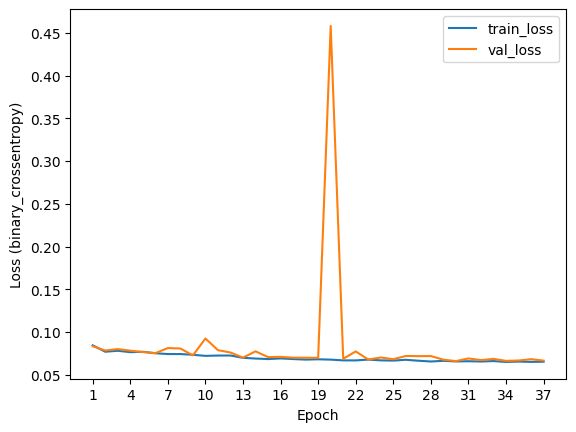

In [19]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = np.arange(1, len(loss) + 1)

plt.plot(epochs, loss, label='train_loss')
plt.plot(epochs, val_loss, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (binary_crossentropy)')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

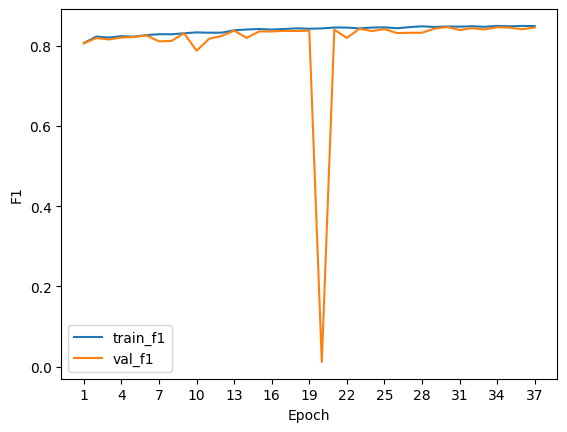

In [20]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
train_f1 = history.history['f1']
val_f1 = history.history['val_f1']

epochs = np.arange(1, len(train_f1) + 1)

plt.plot(epochs, train_f1, label='train_f1')
plt.plot(epochs, val_f1, label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step

--- Displaying Batch 1 ---


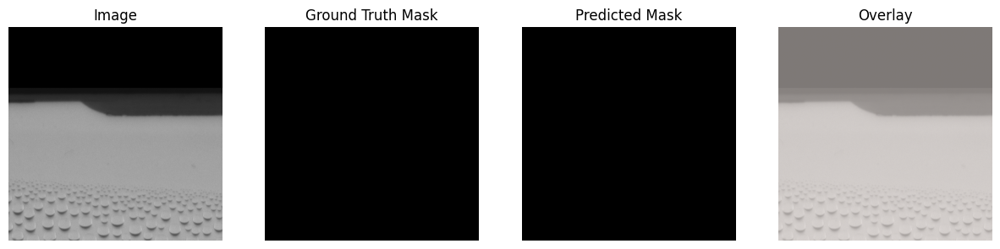

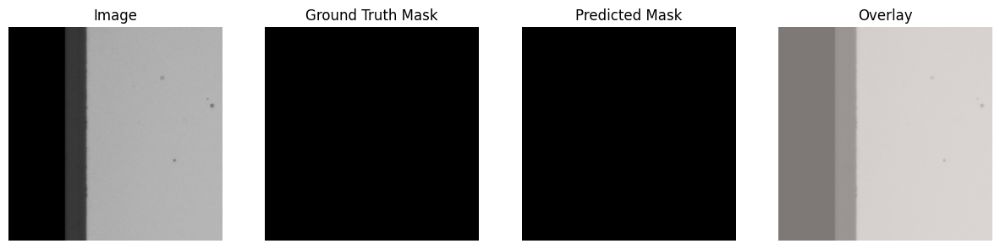

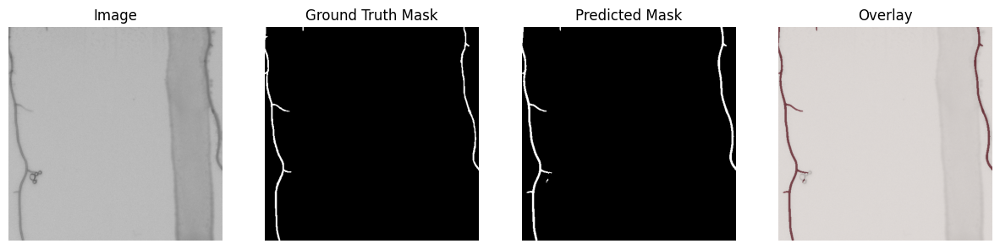

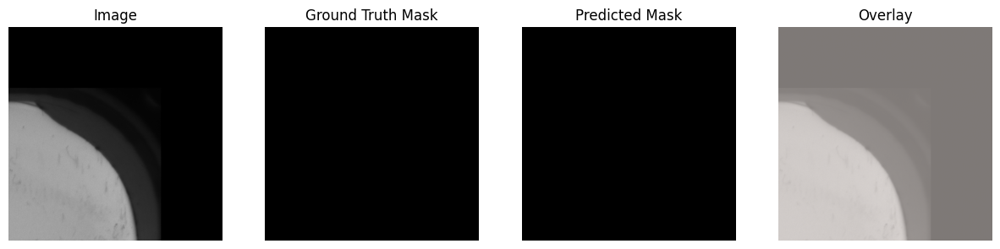

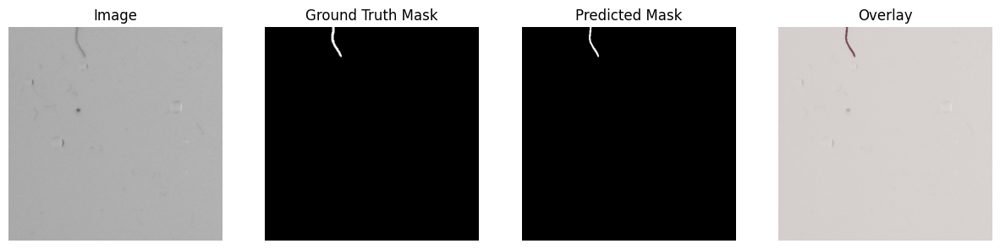

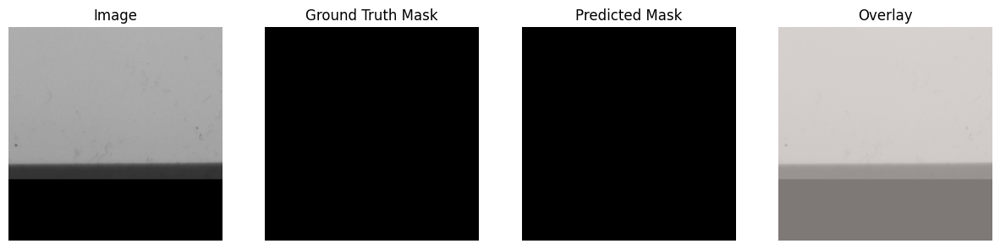

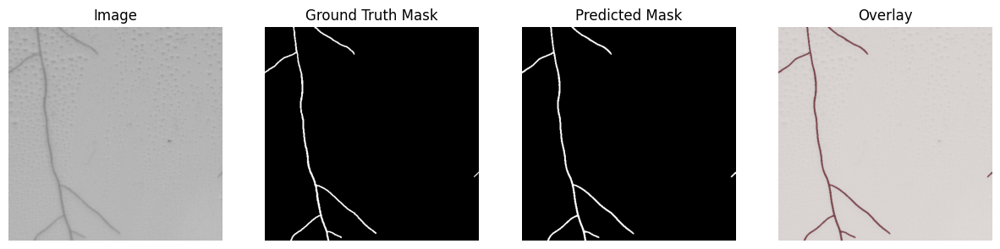

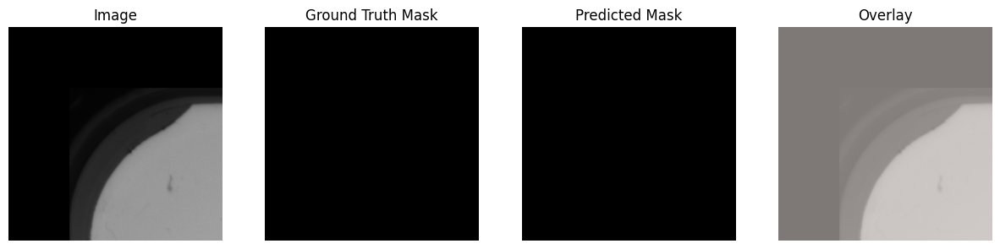

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

--- Displaying Batch 2 ---


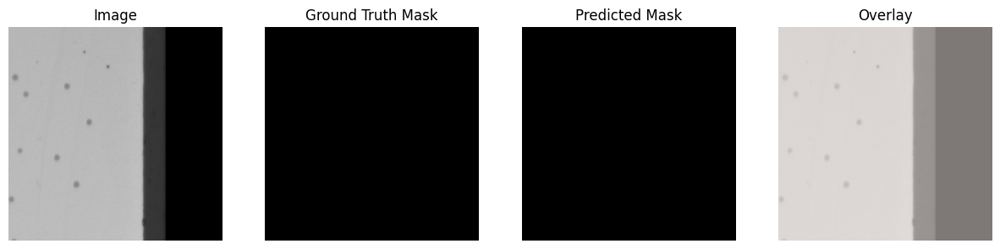

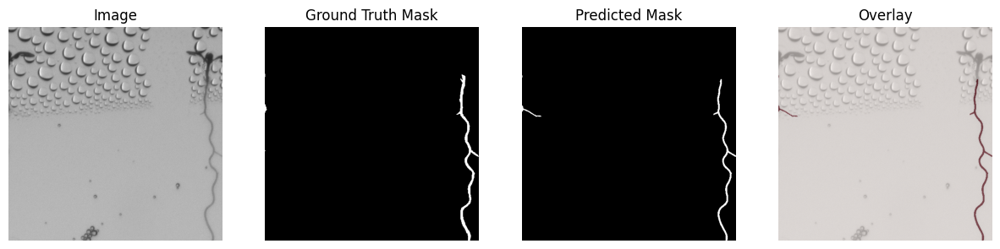

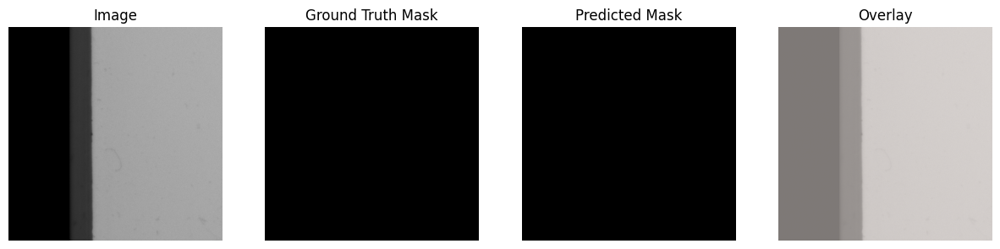

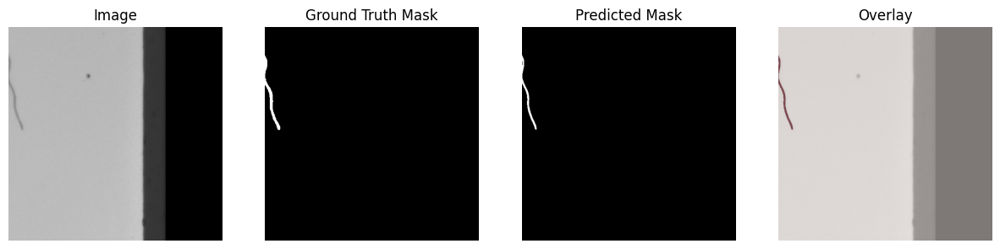

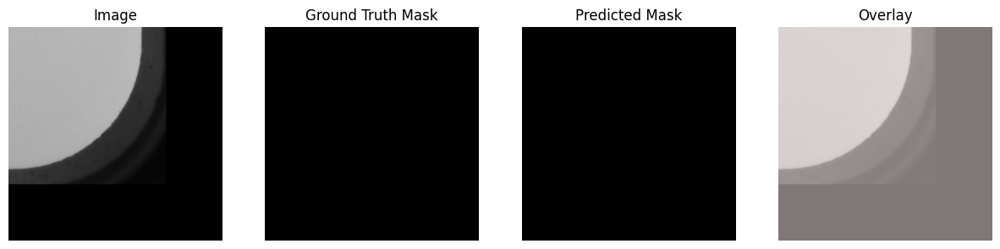

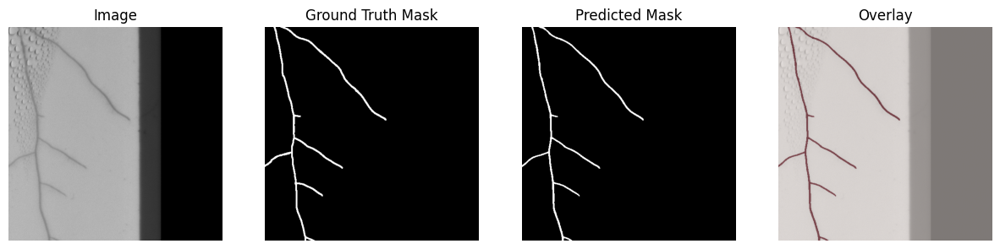

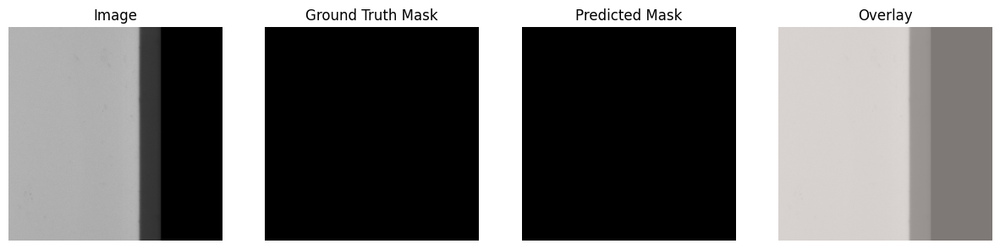

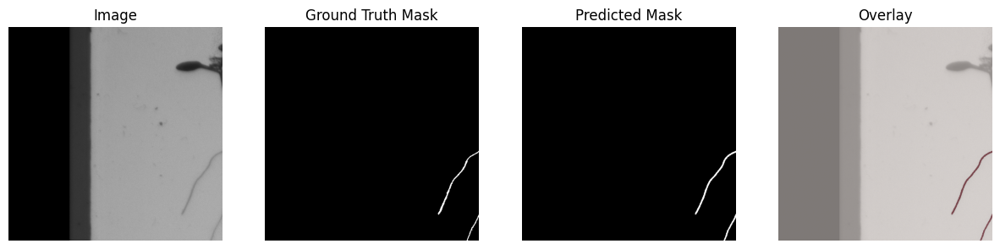

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 858ms/step

--- Displaying Batch 3 ---


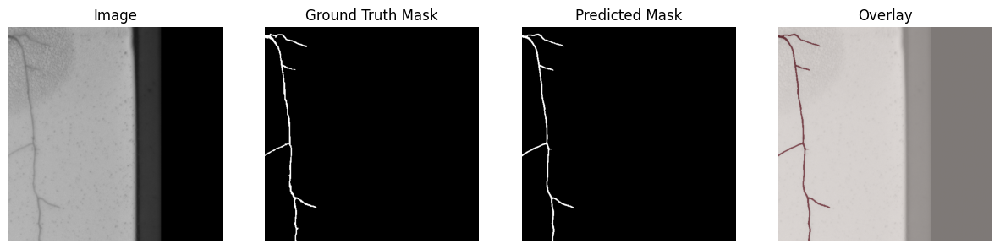

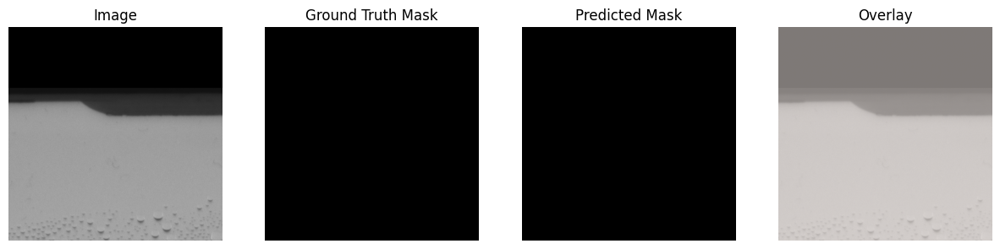

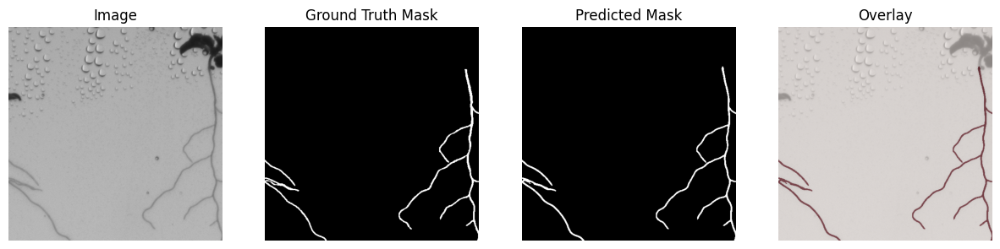

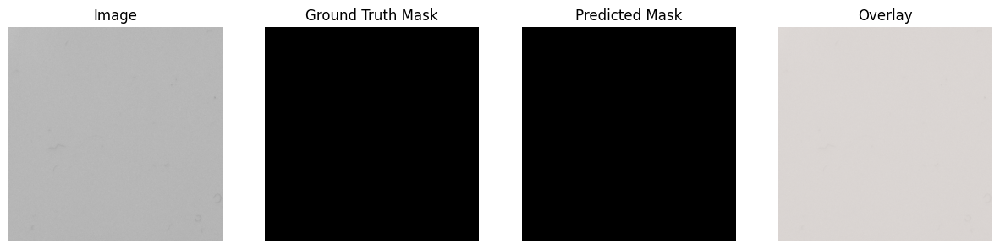

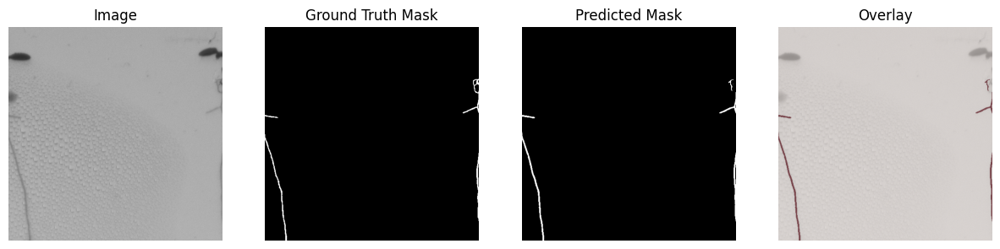

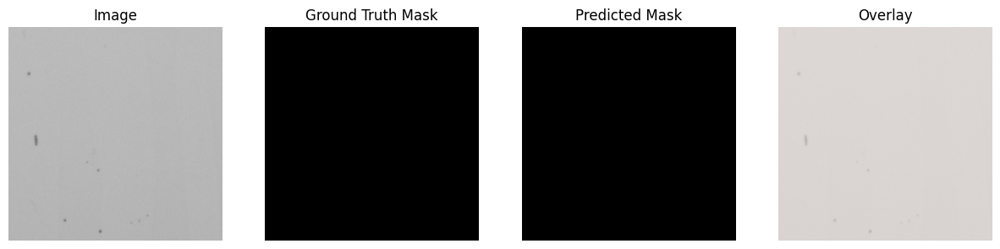

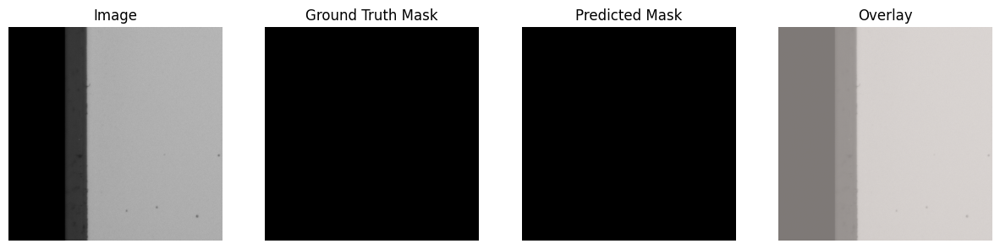

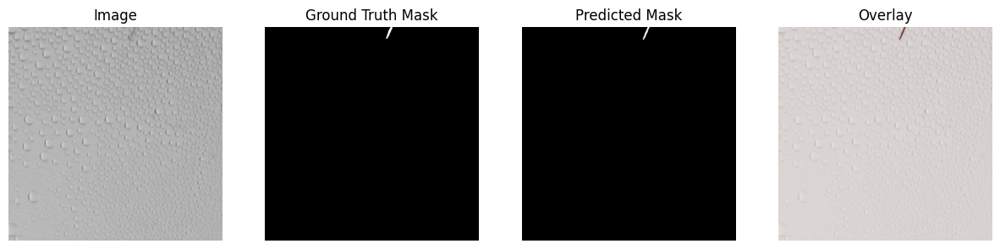

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 806ms/step

--- Displaying Batch 4 ---


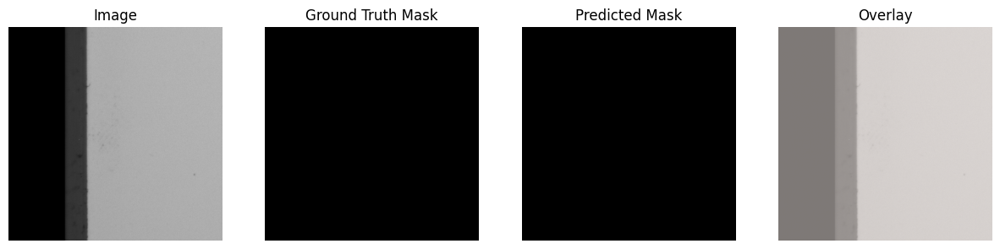

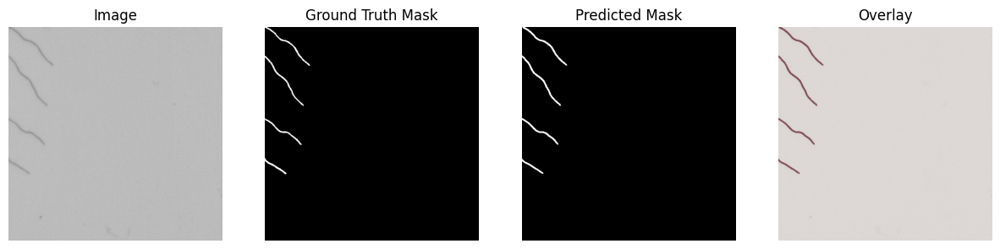

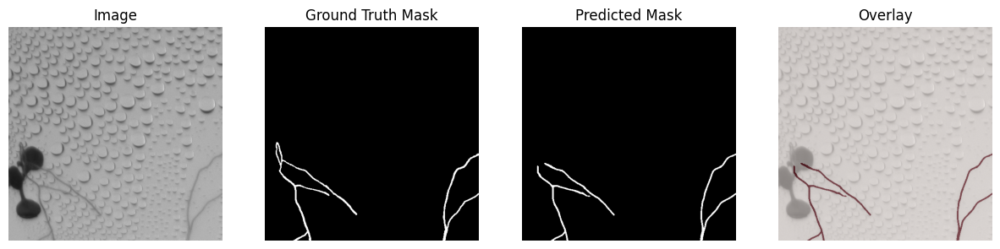

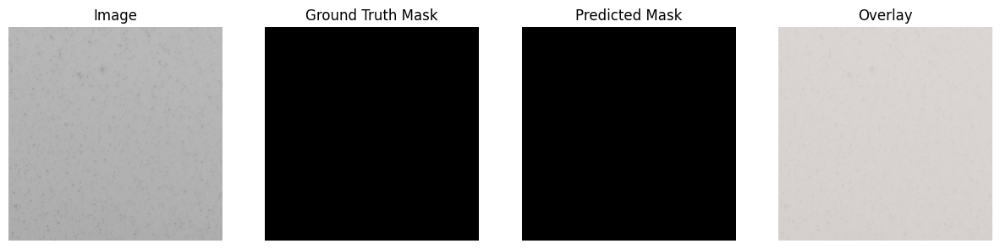

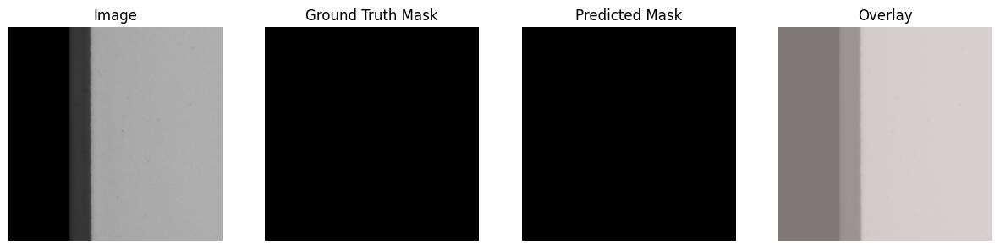

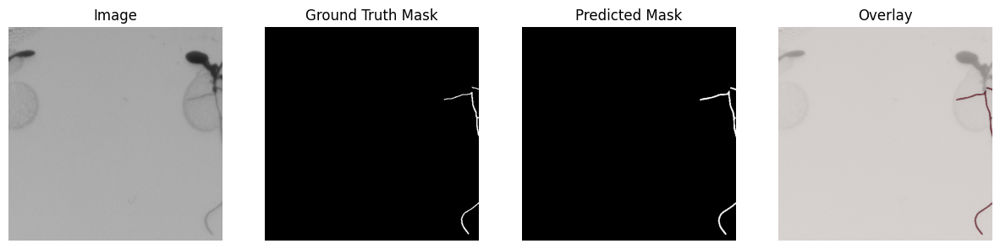

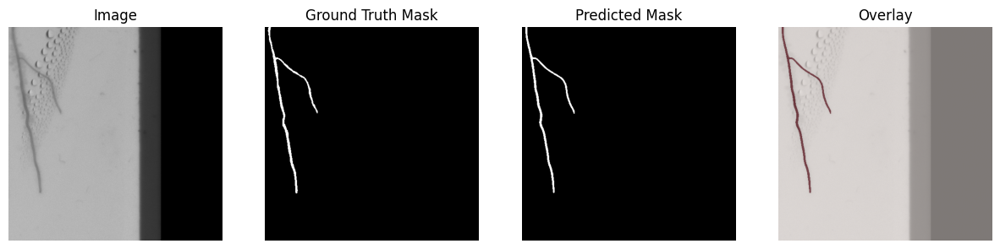

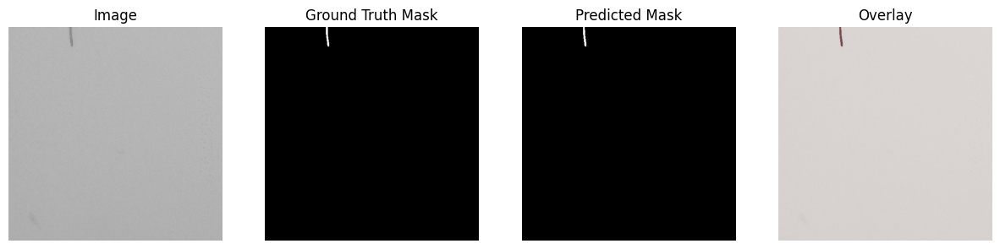

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step

--- Displaying Batch 5 ---


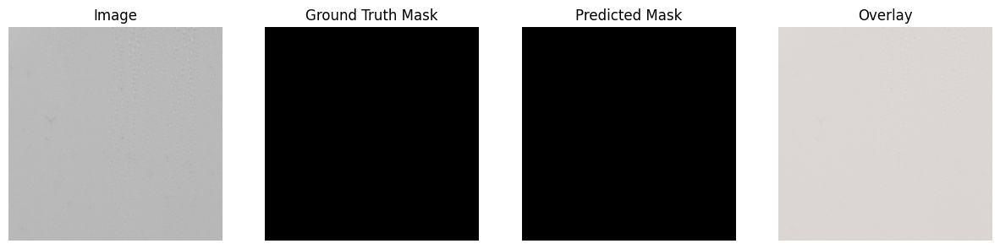

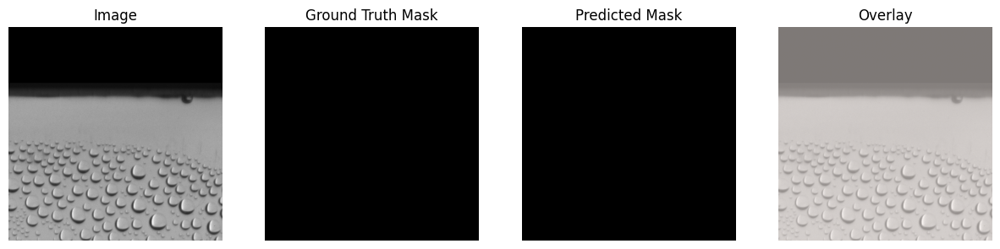

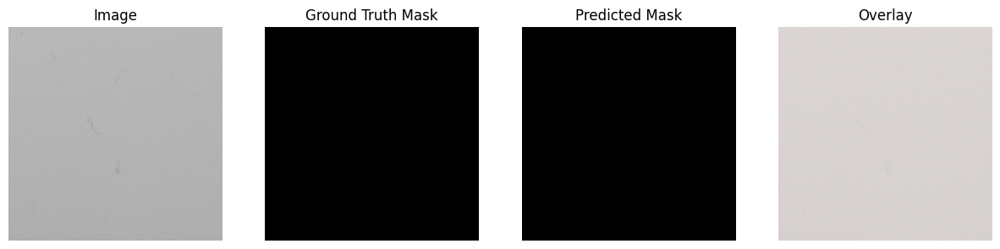

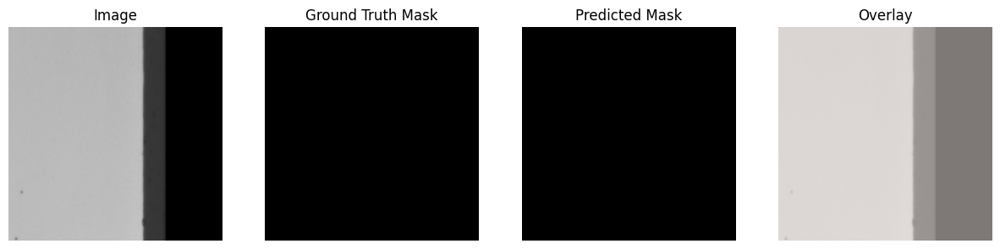

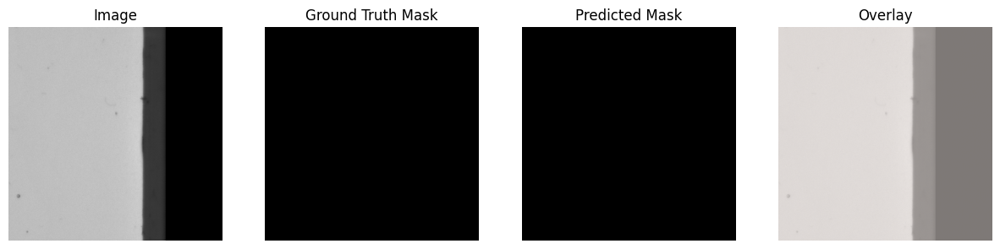

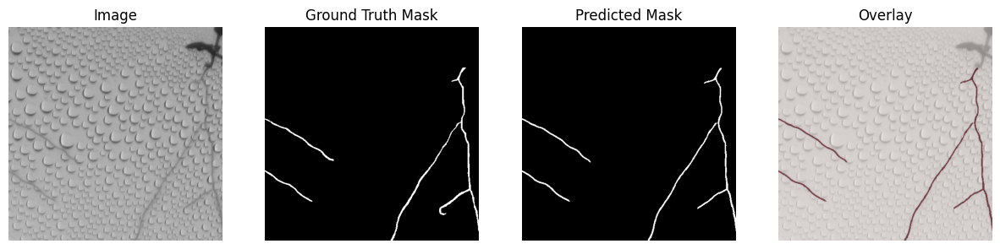

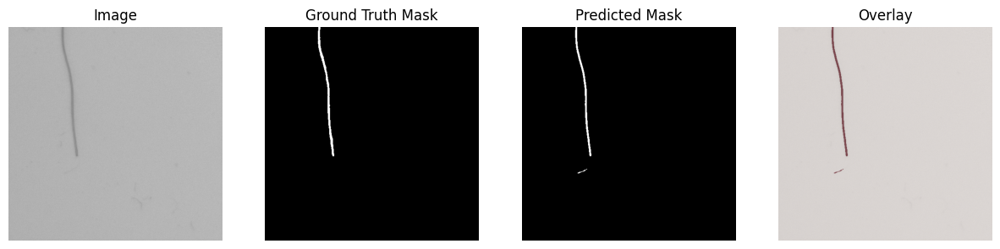

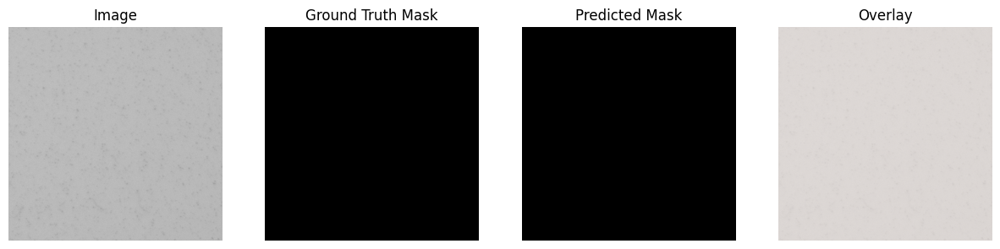

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   

--- Displaying Batch 6 ---


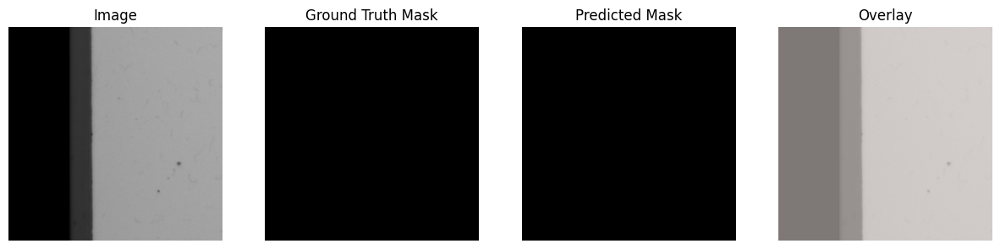

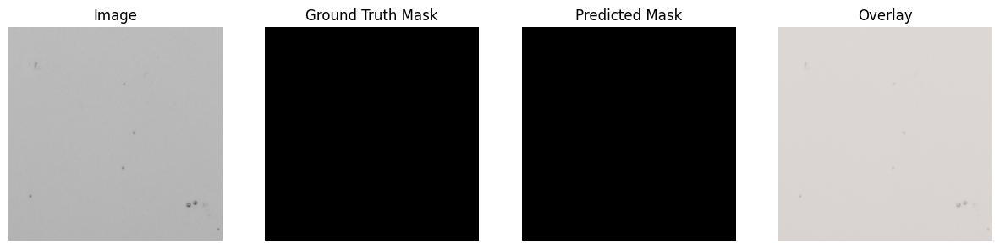

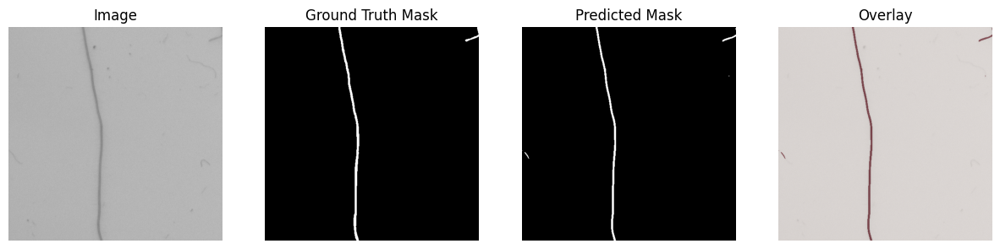

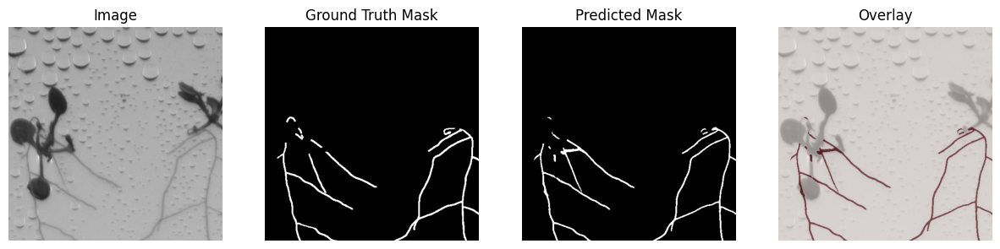

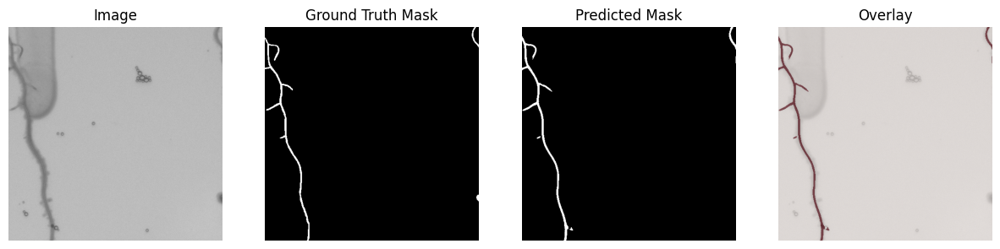

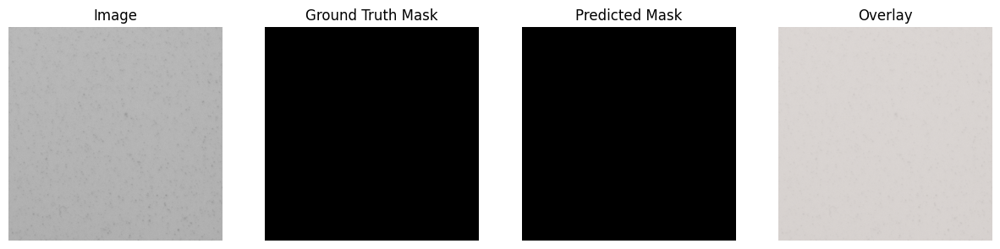

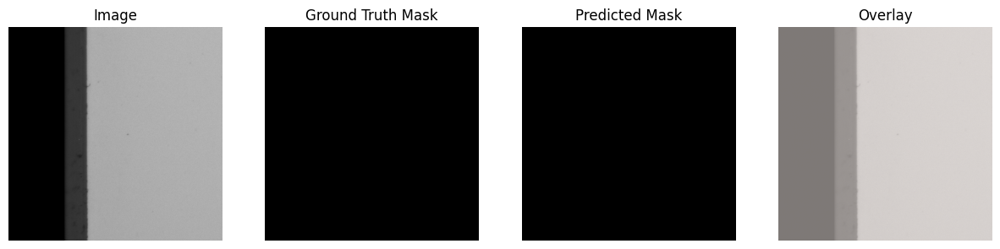

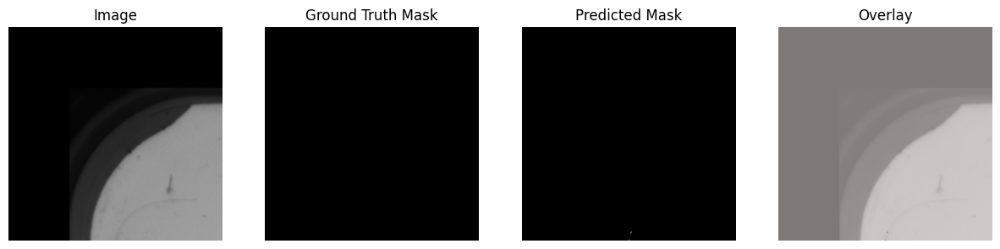

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step

--- Displaying Batch 7 ---


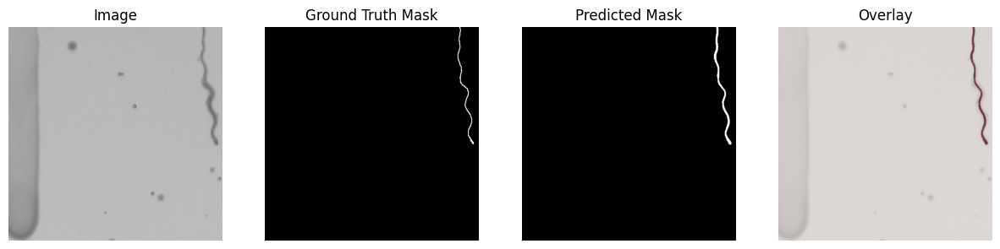

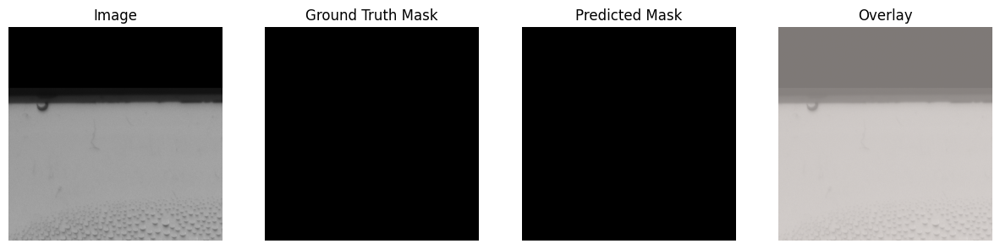

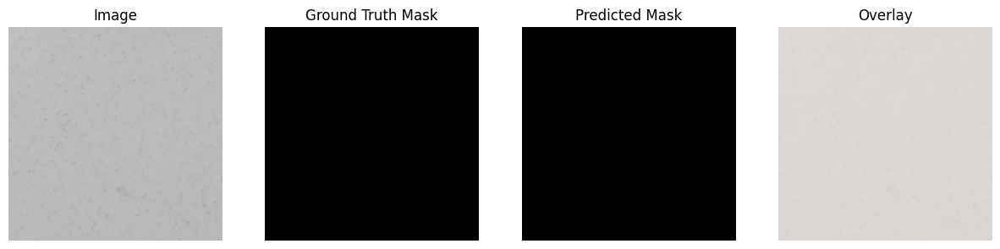

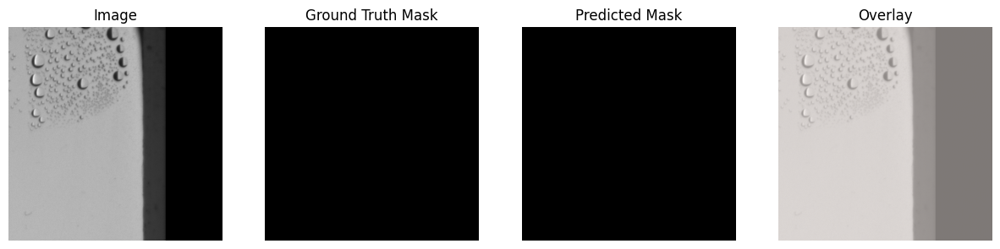

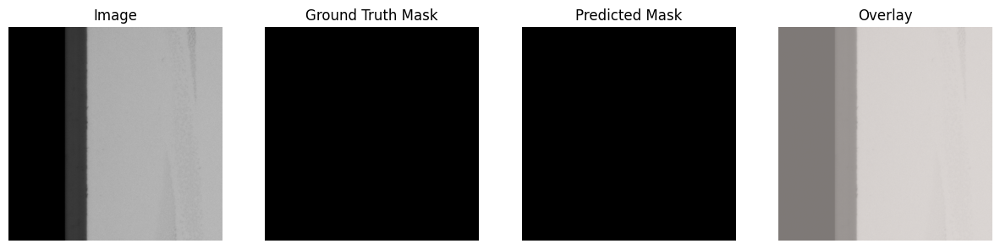

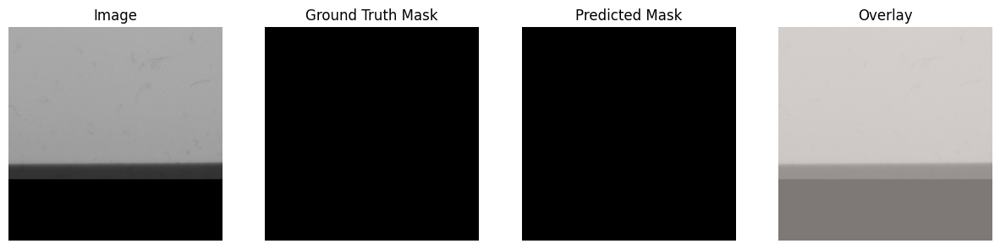

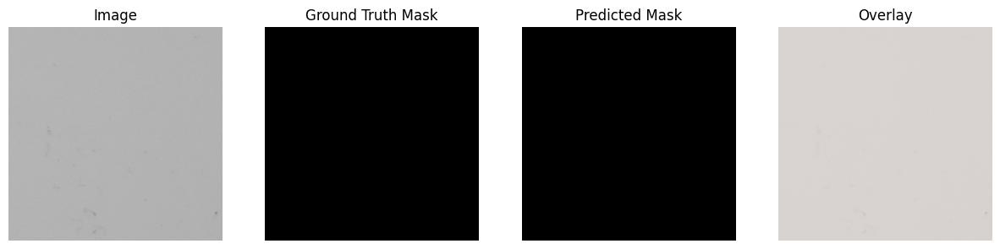

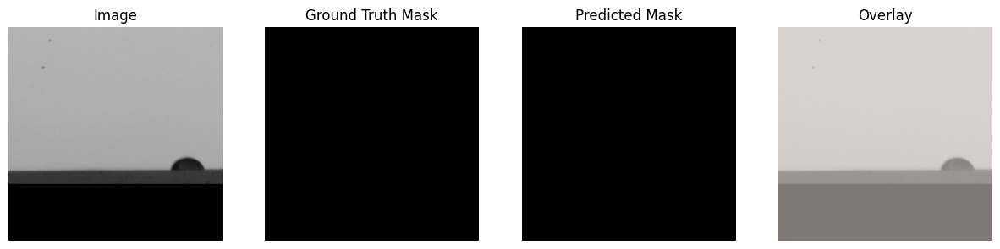

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

--- Displaying Batch 8 ---


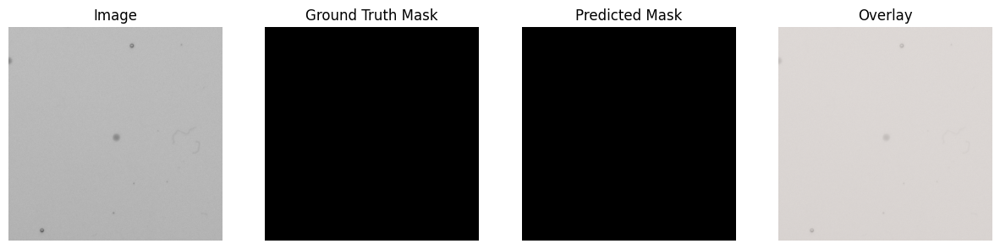

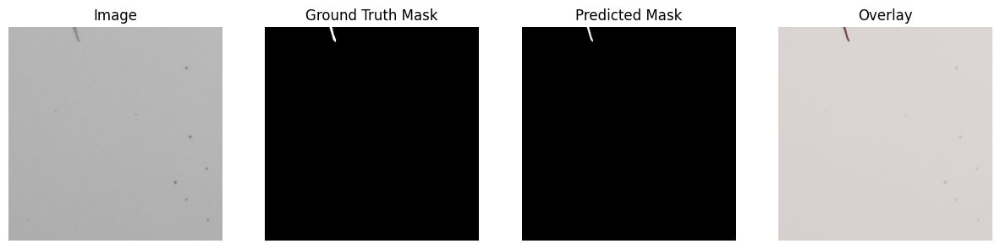

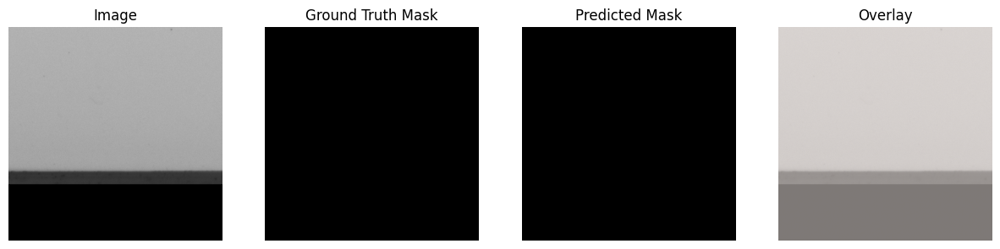

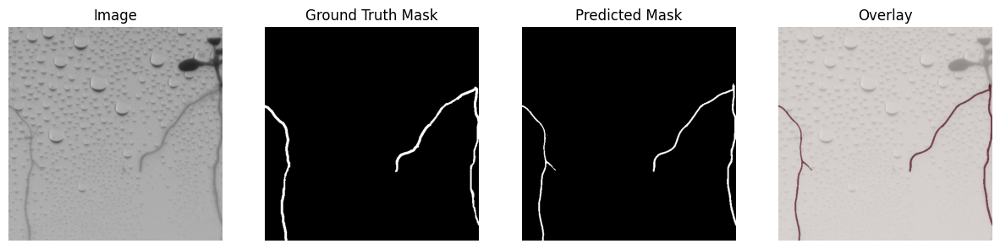

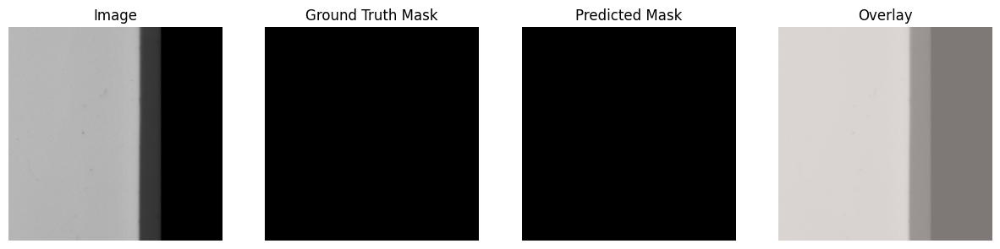

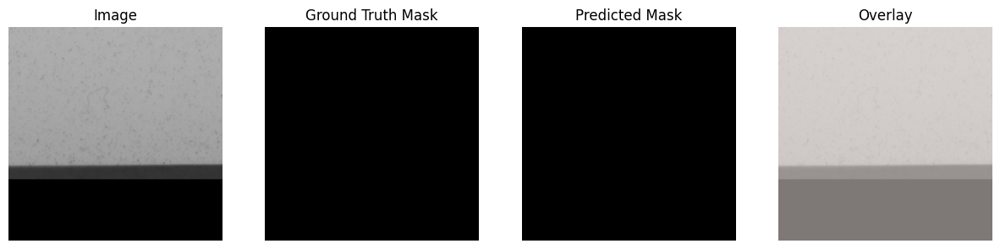

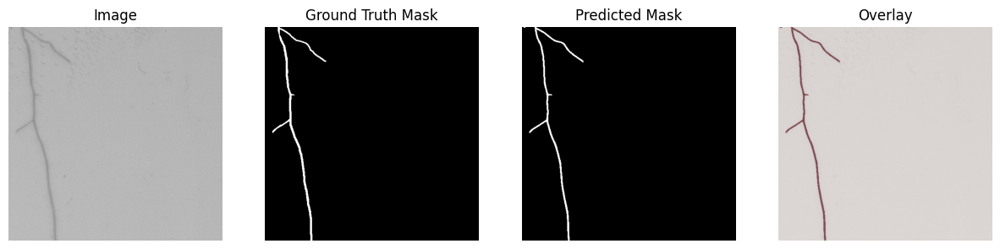

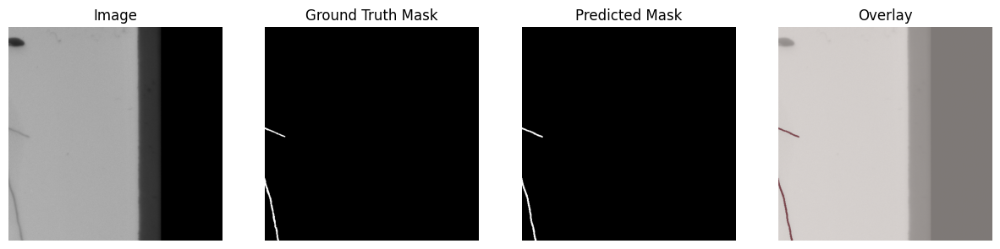

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step   

--- Displaying Batch 9 ---


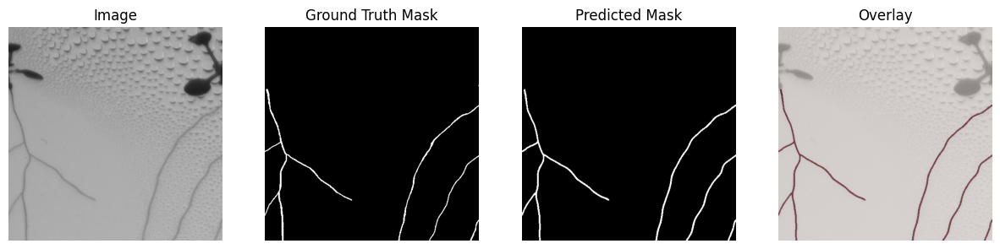

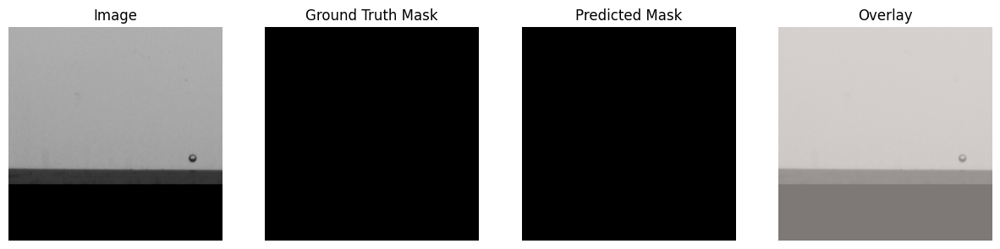

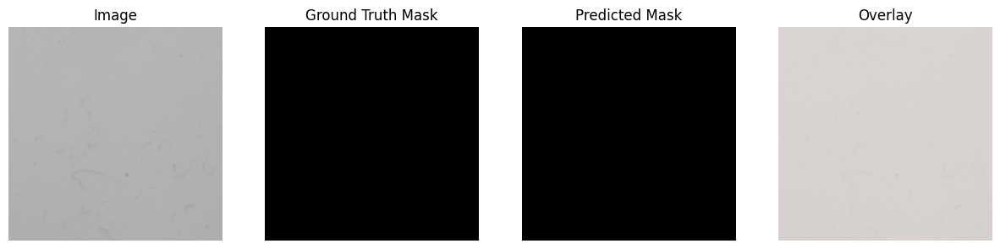

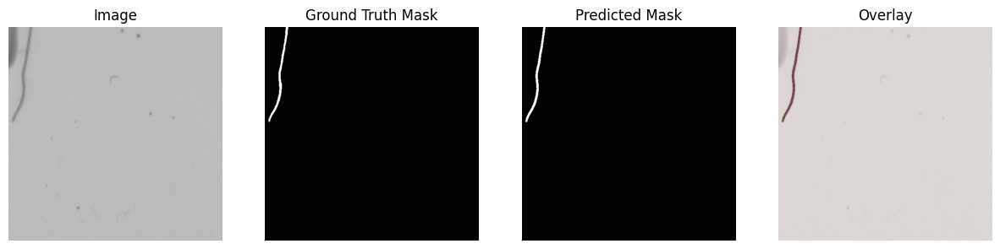

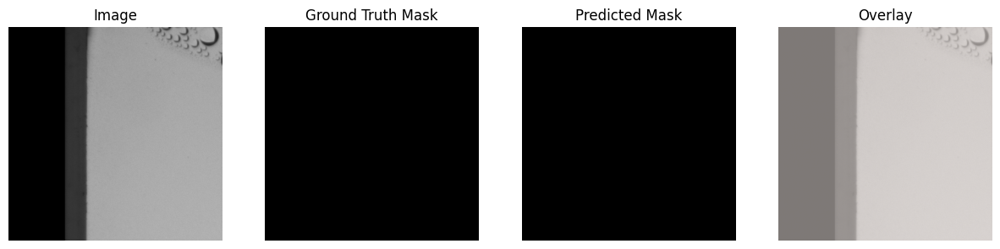

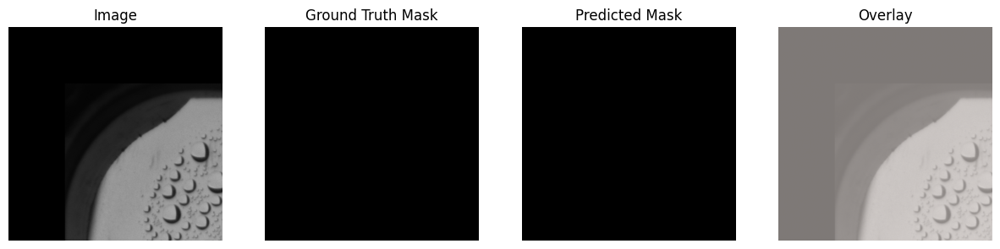

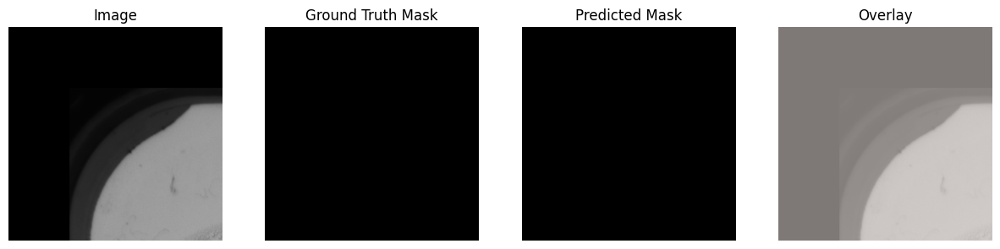

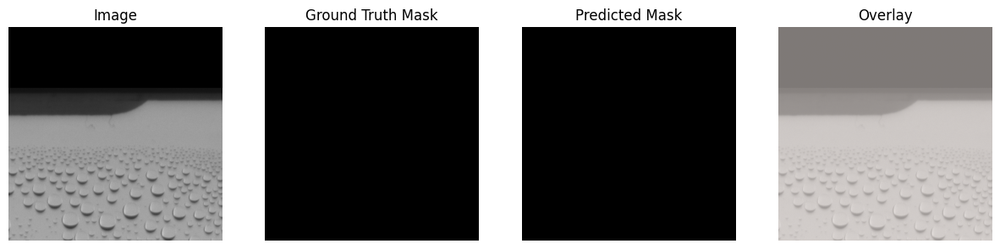

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

--- Displaying Batch 10 ---


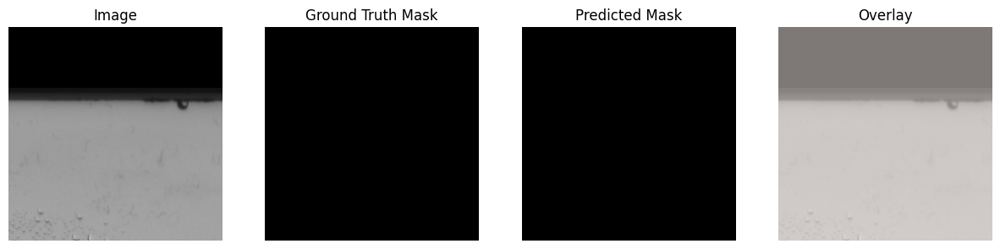

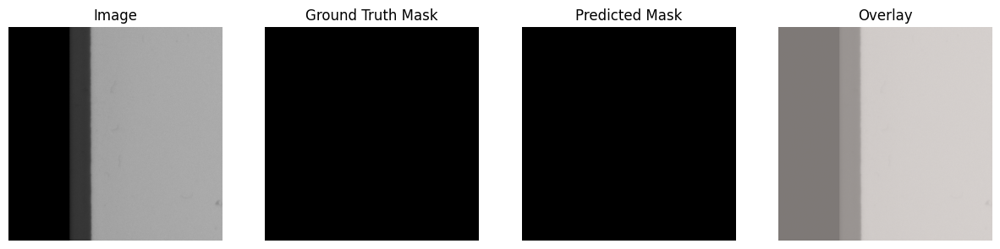

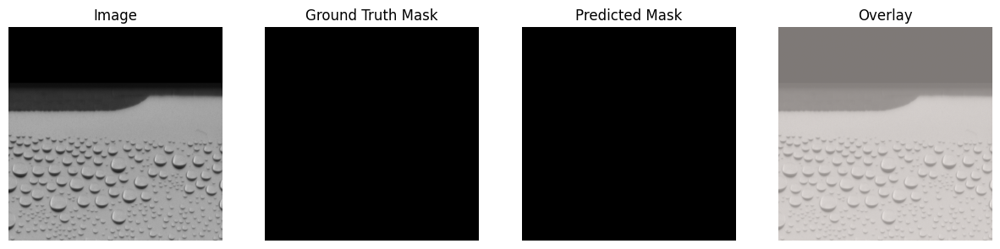

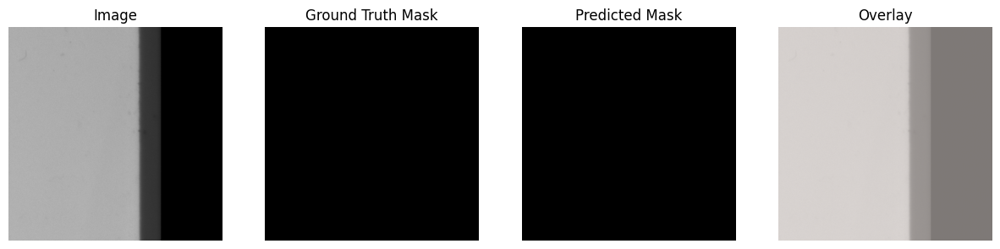

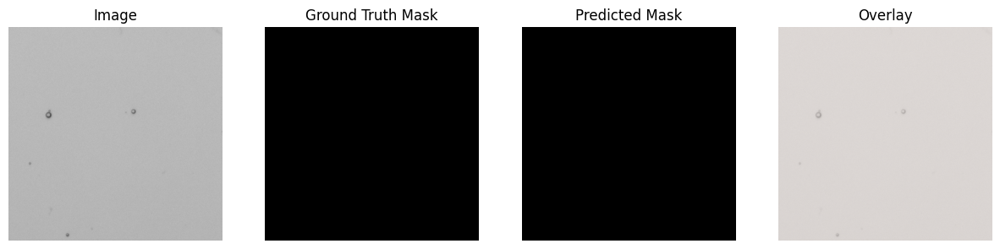

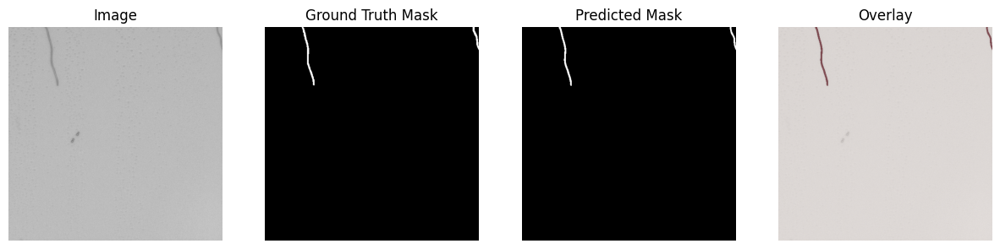

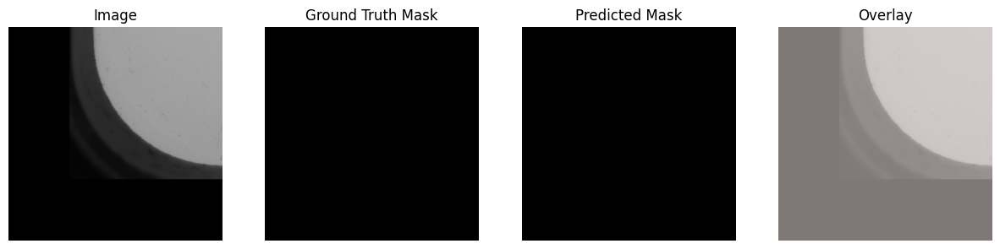

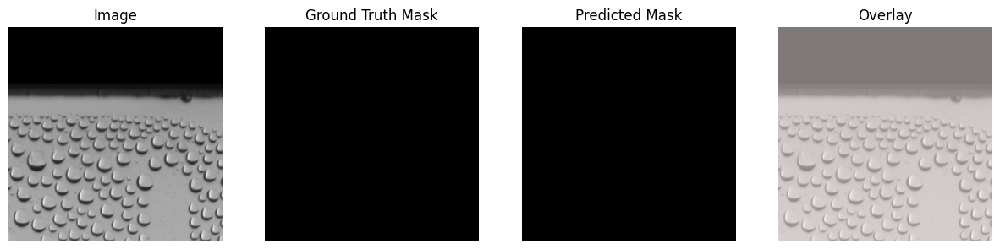


Finished displaying batches.


In [21]:
batch_counter = 0

# Use a while loop to repeatedly get the next batch
while batch_counter < 10:
    try:
        # Get the next batch of data
        images, masks = next(val_generator())
        preds = model.predict(images) 
        
        # Increment the batch counter
        batch_counter += 1
        print(f"\n--- Displaying Batch {batch_counter} ---")

        # --- Your existing plotting logic starts here ---
        
        # If your model outputs logits, convert to probabilities
        # preds = tf.nn.sigmoid(preds).numpy()  # for binary segmentation
        # preds = tf.argmax(preds, axis=-1).numpy()   # for multi-class segmentation
        
        # Determine the actual number of samples in the batch (in case it's smaller than NUM_SAMPLES_PER_BATCH)
        current_num_samples = min(8, images.shape[0])

        for i in range(current_num_samples):
            image = images[i]
            mask = masks[i]
            pred = preds[i]

            # If masks/predictions have channel dimension, squeeze it
            if mask.shape[-1] == 1:
                mask = mask.squeeze(-1)
            if pred.shape[-1] == 1:
                pred = pred.squeeze(-1)

            # Threshold prediction if binary segmentation
            # Note: For multi-class, 'pred' should already be the class index after argmax, 
            # so you would skip this binary step.
            pred_binary = (pred > 0.5).astype(np.uint8) 

            # Plot original image, ground truth, prediction, overlay
            # Increase figure size for better visibility
            plt.figure(figsize=(15, 4)) 

            # Original image
            plt.subplot(1, 4, 1)
            plt.title('Image')
            plt.imshow(image.squeeze(), cmap='gray' if image.shape[-1]==1 else None)
            plt.axis('off')

            # Ground truth mask
            plt.subplot(1, 4, 2)
            plt.title('Ground Truth Mask')
            plt.imshow(mask, cmap='gray')
            plt.axis('off')

            # Predicted mask
            plt.subplot(1, 4, 3)
            plt.title('Predicted Mask')
            plt.imshow(pred_binary, cmap='gray')
            plt.axis('off')

            # Overlay prediction on original image
            plt.subplot(1, 4, 4)
            plt.title('Overlay')
            if image.shape[-1] == 1:
                plt.imshow(image.squeeze(), cmap='gray')
            else:
                plt.imshow(image)
            plt.imshow(pred_binary, cmap='Reds', alpha=0.5)  # overlay prediction
            plt.axis('off')

            plt.show()
            
        # --- Your existing plotting logic ends here ---

    except StopIteration:
        print("\nGenerator is exhausted. No more batches to display.")
        break # Exit the while loop when the generator is empty
    except Exception as e:
        print(f"An error occurred while processing batch {batch_counter}: {e}")
        break

print("\nFinished displaying batches.")

In [22]:
for d in [temp_train_img, temp_train_mask, temp_val_img, temp_val_mask]:
    if os.path.exists(d):
        shutil.rmtree(d)
print("Cleanup complete!")

Cleanup complete!
